# 344. Are kmerseek's region E-values calibrated? Decoy queries against the human proteome

**Question.** When kmerseek reports a region at E-value ≤ E\*, do unrelated queries
produce about that many such regions by chance, in every length and low-complexity
stratum? A region's E-value is the number of regions at least that good that one unrelated
query is expected to turn up in the whole database. So Q unrelated queries should give
about Q × E\* regions at E ≤ E\*. Fewer means the E-value is too large (safe, but it loses
hits). More means it is too small: kmerseek would call chance matches significant.

**What this decides.** Whether kmerseek 0.4.0 ships `region_run_evalue` and
`region_ka_evalue` (seanome/kmerseek
[PR 133](https://github.com/seanome/kmerseek/pull/133)) as E-values. This is a go/no-go
gate on the release, not a new method. A column that fails is either fixed before 0.4.0 or
ships documented as a ranking score, not an E-value.

**Data.**
- Database: the human reference proteome, QfO release 2020_04 (UP000005640, 20_600
  proteins, md5 `74bf5689099474ca85a96b090c722ece`).
- Queries: decoys. A decoy is a human protein with its residues reordered, so every region
  it gets is a chance match. Each protein is shuffled 5 times in each of three ways,
  20_600 × 5 = 103_000 decoys per kind:
  - **dipeptide** (the gate): keeps the first and last residue and the count of every
    adjacent residue pair (Altschul, Stephen F., and Bruce W. Erickson. 1985.
    "Significance of Nucleotide Sequence Alignments: A Method for Random Sequence
    Permutation That Preserves Dinucleotide and Codon Usage." *Molecular Biology and
    Evolution* 2 (6): 526–38). Amino-acid composition and neighbouring-residue counts are
    held, so hydrophobic runs and short repeats survive;
  - **composition** (weaker): residues in a random order; keeps only the count of each
    amino acid;
  - **window10** (stronger): residues shuffled inside each 10-residue stretch, so each
    stretch keeps its hydrophobicity and long low-complexity runs survive.
- Search: kmerseek seanome/kmerseek
  [`0a22970`](https://github.com/seanome/kmerseek/commit/0a229700bc9dbf3d04f9e4f141024ff33b5c4e7e)
  (PR 134's head, which holds PR 133), alphabet `hp_lehninger2` (hydrophobic
  `AFGILMPVWY`, polar `CDEHKNQRST`), k = 19, scaled 1, mismatch penalty 2 and give-up
  margin (X-drop) 8, kmerseek's defaults. The Karlin-Altschul r_database and K are fitted
  once, when the index is built (kmerseek's default 200 database queries). Every other
  search option is kmerseek's default: the whole pipeline, from k-mers to the report
  filters and the choice of regions, runs on the decoys as it would on a real query.
- Pipeline: [`nextflow-runs/region-evalue-calibration`](../nextflow-runs/region-evalue-calibration),
  image `olgabot/kmerseek:2026-10-18-nb344-0a22970`, on Sherlock.

## Pre-registered rule

Written and committed on 2026-10-18, before any decoy was searched. It is not changed
after the run. If it turns out to be wrong, this notebook says so and still reports under
it.

On 2026-10-19, still before any search, Olga chose to keep this rule as written, knowing
from the cell below and from a synthetic check (`scripts/344_synthetic_calibrated_regions.py`)
that it fails a correct E-value at least about half the time (if regions are
independent; more if they are not).

1. **Strata.** 4 length bins (the leaderboard's RULES.md edges, in residues: [0, 100),
   [100, 300), [300, 1000], (1000, ∞)) × 3 bins of the share of residues SEG masks as
   low-complexity ([0, 0.05), [0.05, 0.15), [0.15, 1]; segmasker defaults, window 12, low
   cut 2.2, high cut 2.5; Wootton, John C., and Scott Federhen. 1993. "Statistics of Local
   Complexity in Amino Acid Sequences and Sequence Databases." *Computers & Chemistry*
   17 (2): 149–63). A decoy is placed by its source protein's length and SEG share, so a
   stratum holds the same proteins under all three shuffles. 12 strata.
2. **Cutoffs.** For a stratum with Q_s decoy queries, E\* = 10 / Q_s and E\* = 100 / Q_s,
   so the expected number of chance regions, Q_s × E\*, is 10 and 100. (Q in the task is
   read per stratum. Read as all 103_000 decoys, Q × E\* = 10 would expect 0.03 to 2.3
   regions in a stratum, too few to fall inside a factor of two even when calibrated.)
3. **Count.** Observed = region rows with the column's value ≤ E\*, summed over the
   stratum's decoys and all targets. A row whose value is empty (kmerseek could not
   compute it; for `region_ka_evalue`, a pair with no positive λ) is not counted. The
   count is of regions kmerseek **reports**: with its defaults it drops a pair that
   shares fewer than 2 k-mers, or whose whole-query p-value is above 0.05 and whose best
   region score is below 1.3. Those filters are part of what a user gets, so they stay
   in; they can only lower the count, so they make the E-values look safer, not worse.
   Exclusions, added on 2026-10-18 before any search, once making the decoys showed that
   some shuffles return the protein unchanged: a decoy identical to its source protein,
   or with the same `hp_lehninger2` string as its source (searched in that alphabet it is
   the source itself), is not a decoy and is left out of Q_s; and a region between a
   decoy and its own source protein is not counted, because that one database protein
   shares the decoy's composition and pair counts and so is not unrelated to it. Both
   are counted and printed in section 2.
4. **Pass.** A stratum passes a column at a cutoff if observed is within a factor of two
   of expected: 5 to 20 at expected 10, 50 to 200 at expected 100.
5. **Verdict.** A column passes only if all 12 strata pass at both cutoffs on the
   **dipeptide** decoys. One failed stratum fails the column. 0.4.0 is a **GO** only if
   both columns pass. The composition and window10 decoys are reported beside it, to show
   which null finds the most chance regions, and do not enter the verdict.
   `region_evalue`, the column users filter on, is reported too and is not judged.

The cell below prints these values from `region_evalue_calibration_utils.py`, and the
chance that a correct E-value passes this rule.

In [1]:
import math
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf
import region_evalue_calibration_utils as u

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_fmt_str_lengths(60)

print("strata:")
for s in u.STRATA:
    print("  ", s)
print(
    "expected chance regions per stratum:", u.TARGETS, "| pass band: factor", u.FACTOR
)
print("judged columns:", u.GATE_COLUMNS, "on", u.GATE_KIND, "decoys")

# If chance regions arrived independently, the observed count in a stratum would be
# Poisson with mean equal to the expected count. Then a correct E-value
# passes one stratum at expected 10 with this chance, and at 100 with the next.
p10, p100 = u.chance_inside_factor(10), u.chance_inside_factor(100)
per_column = (p10 * p100) ** len(u.STRATA)
print(
    f"\nA calibrated E-value passes one stratum: {p10:.3f} at expected 10, {p100:.6f} at expected 100"
)
print(f"... all 12 strata at both cutoffs (one column): {per_column:.2f}")
print(f"... both columns, if they were independent: {per_column ** 2:.2f}")

strata:
   <100 aa, SEG <5%
   <100 aa, SEG 5-15%
   <100 aa, SEG >=15%
   100-299 aa, SEG <5%
   100-299 aa, SEG 5-15%
   100-299 aa, SEG >=15%
   300-1000 aa, SEG <5%
   300-1000 aa, SEG 5-15%
   300-1000 aa, SEG >=15%
   >1000 aa, SEG <5%
   >1000 aa, SEG 5-15%
   >1000 aa, SEG >=15%
expected chance regions per stratum: (10, 100) | pass band: factor 2.0
judged columns: ('region_run_evalue', 'region_ka_evalue') on dipeptide decoys

A calibrated E-value passes one stratum: 0.969 at expected 10, 1.000000 at expected 100
... all 12 strata at both cutoffs (one column): 0.69
... both columns, if they were independent: 0.47


The rule fails a correct E-value about half the time on Poisson noise alone,
mostly at expected 10, where a count of 4 or 21 fails. Chance regions are not independent
(one decoy rich in a repeat can hit many targets), which makes the counts spread more and
the chance of a false fail higher. So a fail at expected 10 in one stratum, with expected
100 inside the band, says less than a fail at 100. The verdict still follows the rule; the
table shows which cutoff failed.

## 1. What each shuffle keeps

The three nulls differ in how much low-complexity sequence survives. The figure shows, for
each kind of decoy, the share of its residues SEG masks, against the share in the real
protein it came from.

results: /Users/olga/code/2024-kmerseek-analysis-nb344/nextflow-runs/region-evalue-calibration/results | present: True
shape: (12, 2)
┌────────────────────────┬────────┐
│ stratum                ┆ decoys │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ <100 aa, SEG <5%       ┆ 2420   │
│ <100 aa, SEG 5-15%     ┆ 340    │
│ <100 aa, SEG >=15%     ┆ 1415   │
│ 100-299 aa, SEG <5%    ┆ 11635  │
│ 100-299 aa, SEG 5-15%  ┆ 9725   │
│ 100-299 aa, SEG >=15%  ┆ 7665   │
│ 300-1000 aa, SEG <5%   ┆ 23145  │
│ 300-1000 aa, SEG 5-15% ┆ 23820  │
│ 300-1000 aa, SEG >=15% ┆ 10810  │
│ >1000 aa, SEG <5%      ┆ 3835   │
│ >1000 aa, SEG 5-15%    ┆ 6035   │
│ >1000 aa, SEG >=15%    ┆ 2155   │
└────────────────────────┴────────┘
shape: (3, 5)
┌─────────────┬────────┬──────────────────────────────────┬─────────────────────────┬───────────────────────────────────────────────┐
│ kind        ┆ decoys ┆ median SEG share, source protein ┆ median SEG

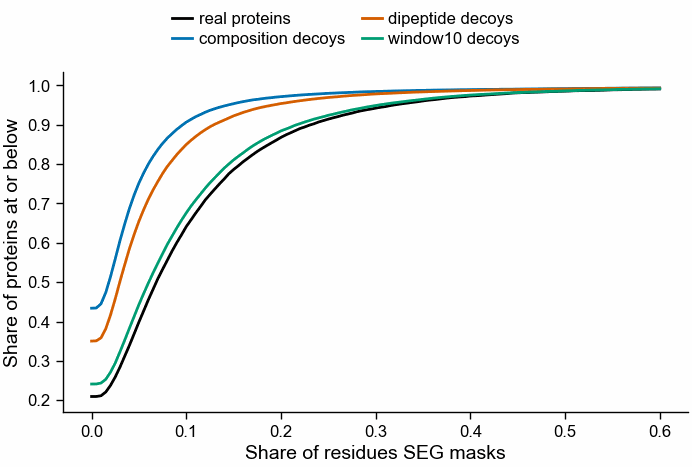

In [2]:
REPO = Path.cwd().parent
RESULTS = Path(
    os.environ.get(
        "NB344_RESULTS",
        REPO / "nextflow-runs" / "region-evalue-calibration" / "results",
    )
)
FIGURES = Path(os.environ.get("NB344_FIGURES", Path.cwd() / "figures" / "344"))
# Set only when the notebook is run on made-up region files
# (scripts/344_synthetic_calibrated_regions.py); drawn on SF1 and SF2.
TEST_LABEL = os.environ.get("NB344_TEST_LABEL", "")
HAVE_RESULTS = (RESULTS / "decoys" / "decoys.tsv").exists()
print("results:", RESULTS, "| present:", HAVE_RESULTS)

KIND_COLOUR = {
    "composition": pf.OKABE_ITO["blue"],
    "dipeptide": pf.OKABE_ITO["vermillion"],
    "window10": pf.OKABE_ITO["bluish_green"],
}
TOOL_LINE = (
    "kmerseek 0a22970, hp_lehninger2 k = 19, penalty 2, X-drop 8 | "
    "query: decoys of 20,600 human proteins | database: human proteome (QfO 2020_04)"
)

if HAVE_RESULTS:
    decoys = u.load_decoys(RESULTS)
    sizes = (
        decoys.filter(pl.col("kind") == u.GATE_KIND)
        .group_by("stratum")
        .len("decoys")
        .join(
            pl.DataFrame({"stratum": u.STRATA, "order": range(len(u.STRATA))}),
            on="stratum",
            how="right",
        )
        .sort("order")
        .select("stratum", pl.col("decoys").fill_null(0))
    )
    print(sizes)
    seg = pl.concat(
        [
            pl.read_csv(RESULTS / "seg" / f"{k}.seg.tsv", separator="\t").with_columns(
                pl.lit(k).alias("kind")
            )
            for k in u.KINDS
        ]
    ).select(
        pl.col("id").alias("decoy_id"),
        pl.col("seg_fraction").alias("decoy_seg_fraction"),
    )
    kept = decoys.join(seg, on="decoy_id", how="left", validate="1:1")
    summary = (
        kept.group_by("kind")
        .agg(
            pl.len().alias("decoys"),
            pl.col("seg_fraction").median().alias("median SEG share, source protein"),
            pl.col("decoy_seg_fraction").median().alias("median SEG share, decoy"),
            (pl.col("decoy_seg_fraction") / pl.col("seg_fraction"))
            .filter(pl.col("seg_fraction") > 0.05)
            .median()
            .alias("median decoy / source, sources with SEG >= 5%"),
        )
        .sort("kind")
    )
    print(summary)

    pf.use_style()
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 60)
    grid = np.linspace(0, 0.6, 121)
    src = np.sort(
        decoys.filter(pl.col("kind") == u.GATE_KIND)["seg_fraction"].to_numpy()
    )
    ax.plot(
        grid,
        np.searchsorted(src, grid, side="right") / len(src),
        color="black",
        label="real proteins",
    )
    for k in u.KINDS:
        v = np.sort(kept.filter(pl.col("kind") == k)["decoy_seg_fraction"].to_numpy())
        ax.plot(
            grid,
            np.searchsorted(v, grid, side="right") / len(v),
            color=KIND_COLOUR[k],
            label=f"{k} decoys",
        )
    ax.set_xlabel("Share of residues SEG masks")
    ax.set_ylabel("Share of proteins at or below")
    pf.shared_legend(fig, ncol=2)
    pf.save(fig, FIGURES / "344_seg_share_by_shuffle_human_proteome")
else:
    print(
        "No results yet: run the pipeline on Sherlock and `make pull-results` (see its Makefile)."
    )

## 2. Observed against expected chance regions, per stratum

One row per decoy kind, stratum, column and cutoff. `n_decoys` is Q_s, `cutoff` is E\*,
`expected` is Q_s × E\*, `observed` the region rows at or below E\*. `ratio` = observed /
expected: 1 is calibrated, above 1 means the E-values are too small (chance regions called
significant), below 1 means too large.

In [3]:
if HAVE_RESULTS:
    regions = {k: u.load_regions(RESULTS, k) for k in u.KINDS}
    table = pl.concat([u.calibration_table(decoys, regions[k], k) for k in u.KINDS])
    for k in u.KINDS:
        s = pl.read_csv(RESULTS / "regions" / f"{k}.summary.tsv", separator="\t")
        print(
            f"{k}: {s['rows_in'].sum():_} region rows reported, {s['rows_kept'].sum():_} with an E-value <= "
            f"{u.KEPT_UP_TO}, {s['rows_ka_empty'].sum():_} with no region_ka_evalue; "
            f"{s['queries_with_rows'].sum():_} of {decoys.filter(pl.col('kind') == k).height:_} decoys got a region"
        )
    for k in u.KINDS:
        t = u.tag_regions(decoys, regions[k], k)
        own = t.filter(pl.col("own_source"))
        n_unchanged = decoys.filter((pl.col("kind") == k) & u.NOT_A_DECOY).height
        print(
            f"  left out for {k}: {n_unchanged} decoys identical to their source or its H/P string "
            f"({t.filter(pl.col('not_a_decoy')).height} region rows), "
            f"{own.height} region rows on the decoy's own source protein "
            f"(smallest region_run_evalue {own['region_run_evalue'].min()})"
        )
    FIGURES.mkdir(parents=True, exist_ok=True)
    table.write_csv(
        FIGURES / "344_calibration_table_human_proteome.tsv", separator="\t"
    )
    gate = table.filter(
        (pl.col("kind") == u.GATE_KIND) & pl.col("column").is_in(u.GATE_COLUMNS)
    )
    print(
        gate.select(
            "column",
            "stratum",
            "n_decoys",
            "cutoff",
            "expected",
            "observed",
            "ratio",
            "inside_factor_two",
        )
    )
    print(
        table.filter(pl.col("kind") != u.GATE_KIND).pivot(
            on="kind", index=["column", "stratum", "expected"], values="ratio"
        )
    )
else:
    print("No results yet.")

composition: 466_056_479 region rows reported, 154_994 with an E-value <= 1.0, 190_273 with no region_ka_evalue; 102_519 of 103_000 decoys got a region
dipeptide: 472_956_090 region rows reported, 190_594 with an E-value <= 1.0, 255_377 with no region_ka_evalue; 102_630 of 103_000 decoys got a region
window10: 560_100_752 region rows reported, 2_395_167 with an E-value <= 1.0, 280_214 with no region_ka_evalue; 102_528 of 103_000 decoys got a region
  left out for composition: 7 decoys identical to their source or its H/P string (0 region rows), 3 region rows on the decoy's own source protein (smallest region_run_evalue 0.208473183434781)
  left out for dipeptide: 135 decoys identical to their source or its H/P string (19345 region rows), 177 region rows on the decoy's own source protein (smallest region_run_evalue 1.9396230411879297e-08)


  left out for window10: 9 decoys identical to their source or its H/P string (0 region rows), 26413 region rows on the decoy's own source protein (smallest region_run_evalue 2.260037570340075e-83)
shape: (48, 8)
┌───────────────────┬────────────────────────┬──────────┬──────────┬──────────┬──────────┬────────┬───────────────────┐
│ column            ┆ stratum                ┆ n_decoys ┆ cutoff   ┆ expected ┆ observed ┆ ratio  ┆ inside_factor_two │
│ ---               ┆ ---                    ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---    ┆ ---               │
│ str               ┆ str                    ┆ i64      ┆ f64      ┆ f64      ┆ i64      ┆ f64    ┆ bool              │
╞═══════════════════╪════════════════════════╪══════════╪══════════╪══════════╪══════════╪════════╪═══════════════════╡
│ region_run_evalue ┆ <100 aa, SEG <5%       ┆ 2291     ┆ 0.004365 ┆ 10.0     ┆ 2        ┆ 0.2    ┆ false             │
│ region_run_evalue ┆ <100 aa, SEG <5%       ┆ 2291     ┆ 0.043649 

**SF1 and SF2: observed / expected chance regions, one figure per column.**

**a**, each of the 12 strata (grouped by length, gaps between groups) at the two cutoffs.
The grey band is the pass band, a factor of two either way; a point inside it passes. A
stratum with no region at the cutoff is drawn on the row marked "0 found". **b**, all
strata together, at every cutoff from expected 1 to expected 100_000 regions. The
dipeptide decoys (vermillion) decide the verdict; the other two show how much the choice
of null matters. In SF2 b the composition and dipeptide lines lie on top of each other.

SF1. region_run_evalue. kmerseek 0a22970, hp_lehninger2 k = 19, penalty 2, X-drop 8 | query: decoys of 20,600 human proteins | database: human proteome (QfO 2020_04)


SF1 region_run_evalue:
shape: (24, 5)
┌────────────────────────┬──────────┬─────────────┬───────────┬──────────┐
│ stratum                ┆ expected ┆ composition ┆ dipeptide ┆ window10 │
│ ---                    ┆ ---      ┆ ---         ┆ ---       ┆ ---      │
│ str                    ┆ f64      ┆ i64         ┆ i64       ┆ i64      │
╞════════════════════════╪══════════╪═════════════╪═══════════╪══════════╡
│ <100 aa, SEG <5%       ┆ 10.0     ┆ 1           ┆ 2         ┆ 5        │
│ <100 aa, SEG <5%       ┆ 100.0    ┆ 34          ┆ 30        ┆ 30       │
│ <100 aa, SEG 5-15%     ┆ 10.0     ┆ 4           ┆ 12        ┆ 11       │
│ <100 aa, SEG 5-15%     ┆ 100.0    ┆ 49          ┆ 99        ┆ 93       │
│ <100 aa, SEG >=15%     ┆ 10.0     ┆ 2630        ┆ 9         ┆ 4714     │
│ <100 aa, SEG >=15%     ┆ 100.0    ┆ 4931        ┆ 114       ┆ 7822     │
│ 100-299 aa, SEG <5%    ┆ 10.0     ┆ 4           ┆ 6         ┆ 6        │
│ 100-299 aa, SEG <5%    ┆ 100.0    ┆ 60          ┆ 62        

SF2 region_ka_evalue:
shape: (24, 5)
┌────────────────────────┬──────────┬─────────────┬───────────┬──────────┐
│ stratum                ┆ expected ┆ composition ┆ dipeptide ┆ window10 │
│ ---                    ┆ ---      ┆ ---         ┆ ---       ┆ ---      │
│ str                    ┆ f64      ┆ i64         ┆ i64       ┆ i64      │
╞════════════════════════╪══════════╪═════════════╪═══════════╪══════════╡
│ <100 aa, SEG <5%       ┆ 10.0     ┆ 0           ┆ 0         ┆ 0        │
│ <100 aa, SEG <5%       ┆ 100.0    ┆ 1           ┆ 2         ┆ 0        │
│ <100 aa, SEG 5-15%     ┆ 10.0     ┆ 3           ┆ 3         ┆ 6        │
│ <100 aa, SEG 5-15%     ┆ 100.0    ┆ 17          ┆ 33        ┆ 36       │
│ <100 aa, SEG >=15%     ┆ 10.0     ┆ 1884        ┆ 23        ┆ 2203     │
│ <100 aa, SEG >=15%     ┆ 100.0    ┆ 3645        ┆ 135       ┆ 4302     │
│ 100-299 aa, SEG <5%    ┆ 10.0     ┆ 0           ┆ 0         ┆ 0        │
│ 100-299 aa, SEG <5%    ┆ 100.0    ┆ 3           ┆ 7         ┆

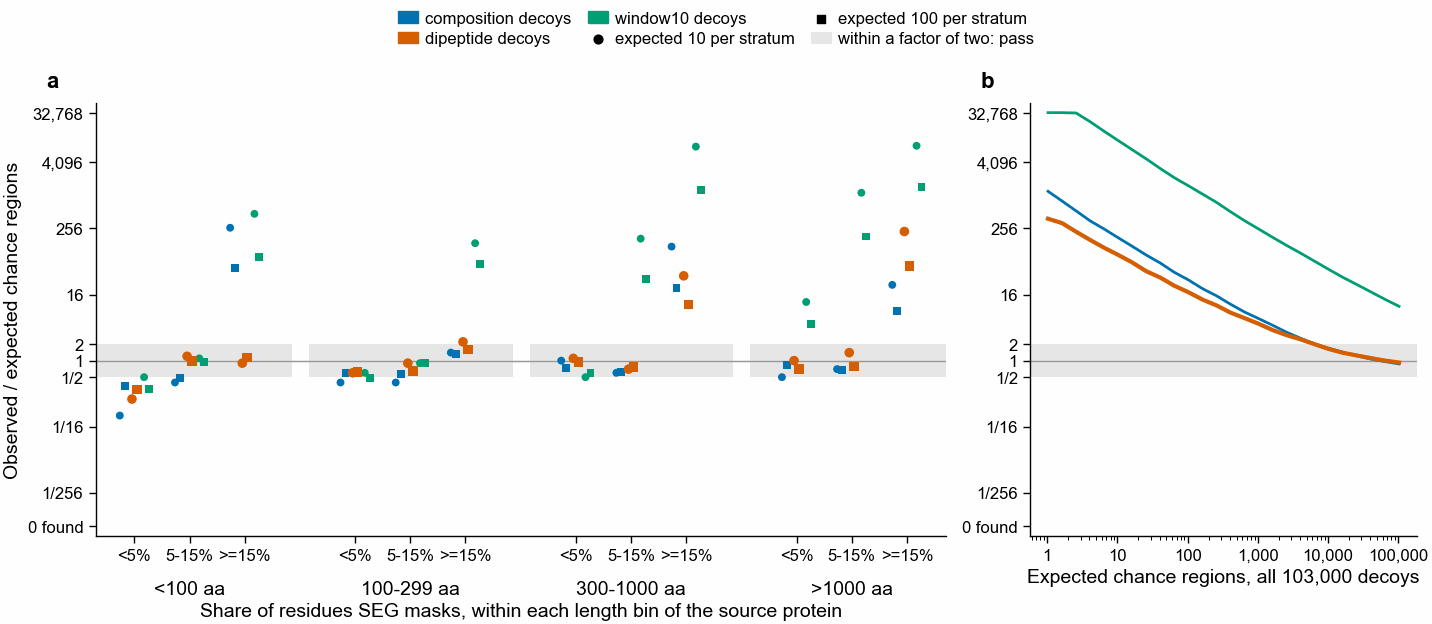

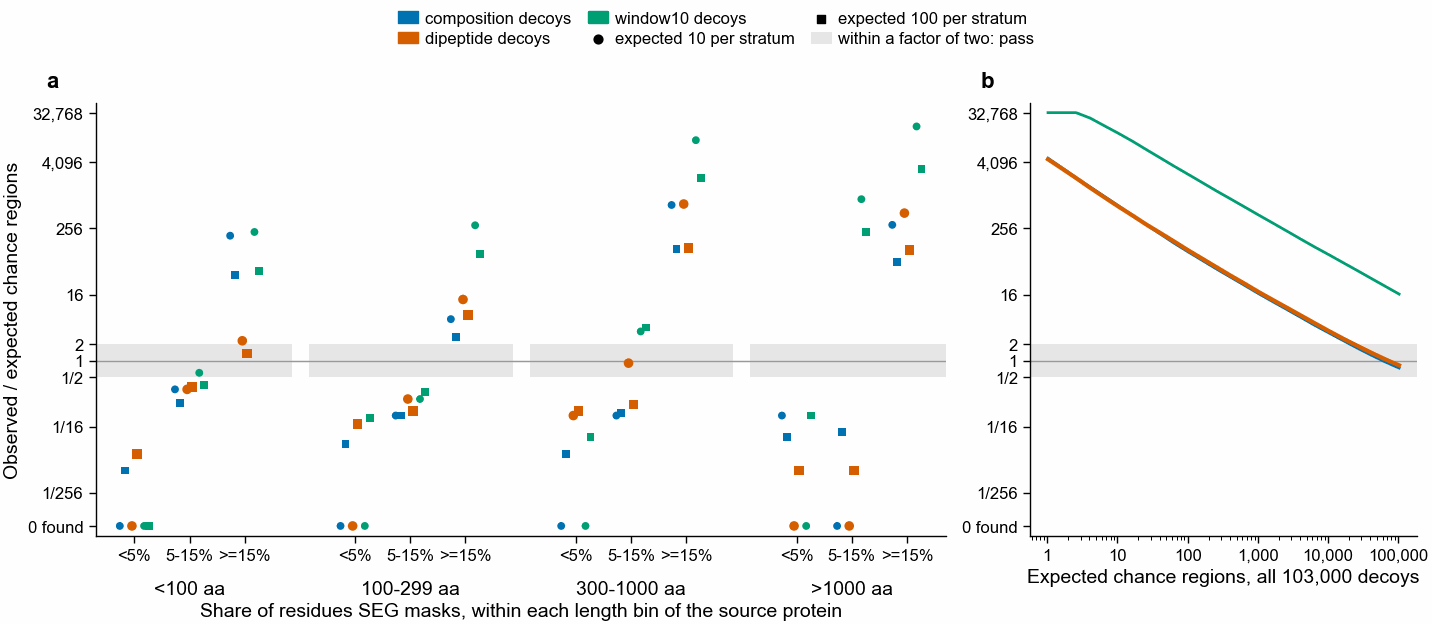

In [4]:
# Ratios run from 1 found where 100 were expected (1/100) to about 18,000 times too many,
# so the axis covers 1/256 to 32,768 and a stratum with none found sits below it.
FLOOR, CEIL = 1 / 1024, 32_768
TICKS = [1 / 256, 1 / 16, 1 / 2, 1, 2, 16, 256, 4096, 32_768]
TICK_LABELS = ["1/256", "1/16", "1/2", "1", "2", "16", "256", "4,096", "32,768"]


def ratio_for_plot(r):
    return FLOOR if r == 0 else min(r, CEIL)


def draw_sf(column, sf):
    print(f"SF{sf}. {column}. {TOOL_LINE}")
    pf.use_style()
    fig, (a, b) = pf.figure(
        pf.TWO_COLUMN_MM, 80, ncols=2, gridspec_kw={"width_ratios": [2.2, 1]}
    )
    xs, labels = [], []
    for g, (lname, _, _) in enumerate(u.LENGTH_BINS):
        for j, (sname, _, _) in enumerate(u.SEG_BINS):
            xs.append(g * 4 + j)
            labels.append(f"{sname.replace('SEG ', '')}")
    for ax in (a, b):
        ax.axhspan(1 / u.FACTOR, u.FACTOR, color="#e6e6e6", zorder=0, lw=0)
        ax.axhline(1, color=pf.GREY, lw=0.5, zorder=1)
        ax.set_yscale("log", base=2)
        ax.set_yticks([FLOOR] + TICKS, ["0 found"] + TICK_LABELS)
        ax.set_ylim(FLOOR / 1.5, CEIL * 1.5)
    t = table.filter(pl.col("column") == column)
    for ki, k in enumerate(u.KINDS):
        for ti, (target, marker) in enumerate(zip(u.TARGETS, ("o", "s"))):
            rows = t.filter((pl.col("kind") == k) & (pl.col("expected") == target))
            ys = [
                ratio_for_plot(rows.filter(pl.col("stratum") == s)["ratio"][0])
                for s in u.STRATA
            ]
            dx = (ki - 1) * 0.22 + (ti - 0.5) * 0.09
            a.scatter(
                [x + dx for x in xs],
                ys,
                marker=marker,
                s=12 if k == u.GATE_KIND else 8,
                color=KIND_COLOUR[k],
                edgecolor="none",
                zorder=3 if k == u.GATE_KIND else 2,
                label=None,
            )
    for k in u.KINDS:
        a.fill_between([], [], color=KIND_COLOUR[k], label=f"{k} decoys")
    for target, marker in zip(u.TARGETS, ("o", "s")):
        a.scatter(
            [],
            [],
            marker=marker,
            color="black",
            s=10,
            label=f"expected {target} per stratum",
        )
    a.fill_between([], [], color="#e6e6e6", label="within a factor of two: pass")
    for x in range(4, 16, 4):
        a.axvline(x - 1.0, color="white", lw=6, zorder=0)
    a.set_xticks(xs, labels, rotation=0)
    for g, (lname, _, _) in enumerate(u.LENGTH_BINS):
        a.annotate(
            lname,
            xy=(g * 4 + 1, 0),
            xycoords=("data", "axes fraction"),
            xytext=(0, -16),
            textcoords="offset points",
            ha="center",
            va="top",
        )
    a.set_xlabel(
        "Share of residues SEG masks, within each length bin of the source protein",
        labelpad=14,
    )
    a.set_ylabel("Observed / expected chance regions")
    a.set_xlim(-0.7, xs[-1] + 0.7)
    cutoffs = list(np.logspace(-5, 0, 26))
    for k in u.KINDS:
        c = u.observed_curve(decoys, regions[k], k, column, cutoffs).filter(
            pl.col("expected") >= 1
        )
        b.plot(
            c["expected"],
            [ratio_for_plot(o / e) for o, e in zip(c["observed"], c["expected"])],
            color=KIND_COLOUR[k],
            lw=1.5 if k == u.GATE_KIND else 1,
        )
    b.set_xscale("log")
    b.set_xticks(
        [1, 10, 100, 1000, 10_000, 100_000],
        ["1", "10", "100", "1,000", "10,000", "100,000"],
    )
    b.set_xlabel("Expected chance regions, all 103,000 decoys")
    pf.shared_legend(fig, ncol=3)
    pf.panel_label(a, "a")
    pf.panel_label(b, "b")
    if TEST_LABEL:
        a.text(0.5, 0.92, TEST_LABEL, transform=a.transAxes, ha="center", color="black")
    pf.save(
        fig,
        FIGURES
        / f"344_sf{sf}_{column}_observed_vs_expected_dipeptide_decoys_human_proteome",
    )
    return fig


if HAVE_RESULTS:
    for sf, column in enumerate(u.GATE_COLUMNS, start=1):
        draw_sf(column, sf)
        print(f"SF{sf} {column}:")
        print(
            table.filter(pl.col("column") == column).pivot(
                on="kind", index=["stratum", "expected"], values="observed"
            )
        )
else:
    print("No results yet.")

All strata together: regions at or below each cutoff for the three kinds of decoy, and how
many times the dipeptide count the other two kinds give. `expected` is all decoys of a kind
(after the exclusions) times the cutoff.

In [5]:
if HAVE_RESULTS:
    for column in u.GATE_COLUMNS:
        parts = [
            u.observed_curve(
                decoys, regions[k], k, column, [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
            ).select("cutoff", "expected", pl.col("observed").alias(k))
            for k in u.KINDS
        ]
        pooled = (
            parts[1]
            .join(parts[0].drop("expected"), on="cutoff")
            .join(parts[2].drop("expected"), on="cutoff")
            .with_columns(
                (pl.col("composition") / pl.col("dipeptide"))
                .round(2)
                .alias("composition / dipeptide"),
                (pl.col("window10") / pl.col("dipeptide"))
                .round(1)
                .alias("window10 / dipeptide"),
            )
        )
        print(column)
        print(pooled)
else:
    print("No results yet.")

region_run_evalue
shape: (5, 7)
┌────────┬──────────┬───────────┬─────────────┬──────────┬─────────────────────────┬──────────────────────┐
│ cutoff ┆ expected ┆ dipeptide ┆ composition ┆ window10 ┆ composition / dipeptide ┆ window10 / dipeptide │
│ ---    ┆ ---      ┆ ---       ┆ ---         ┆ ---      ┆ ---                     ┆ ---                  │
│ f64    ┆ f64      ┆ i64       ┆ i64         ┆ i64      ┆ f64                     ┆ f64                  │
╞════════╪══════════╪═══════════╪═════════════╪══════════╪═════════════════════════╪══════════════════════╡
│ 0.0001 ┆ 10.2865  ┆ 866       ┆ 1778        ┆ 104819   ┆ 2.05                    ┆ 121.0                │
│ 0.001  ┆ 102.865  ┆ 1812      ┆ 3035        ┆ 157308   ┆ 1.67                    ┆ 86.8                 │
│ 0.01   ┆ 1028.65  ┆ 4824      ┆ 6000        ┆ 256848   ┆ 1.24                    ┆ 53.2                 │
│ 0.1    ┆ 10286.5  ┆ 16729     ┆ 17301       ┆ 470558   ┆ 1.03                    ┆ 28.1               

region_ka_evalue
shape: (5, 7)
┌────────┬──────────┬───────────┬─────────────┬──────────┬─────────────────────────┬──────────────────────┐
│ cutoff ┆ expected ┆ dipeptide ┆ composition ┆ window10 ┆ composition / dipeptide ┆ window10 / dipeptide │
│ ---    ┆ ---      ┆ ---       ┆ ---         ┆ ---      ┆ ---                     ┆ ---                  │
│ f64    ┆ f64      ┆ i64       ┆ i64         ┆ i64      ┆ f64                     ┆ f64                  │
╞════════╪══════════╪═══════════╪═════════════╪══════════╪═════════════════════════╪══════════════════════╡
│ 0.0001 ┆ 10.2865  ┆ 6618      ┆ 6816        ┆ 142631   ┆ 1.03                    ┆ 21.6                 │
│ 0.001  ┆ 102.865  ┆ 10453     ┆ 9772        ┆ 252589   ┆ 0.93                    ┆ 24.2                 │
│ 0.01   ┆ 1028.65  ┆ 18296     ┆ 17045       ┆ 461376   ┆ 0.93                    ┆ 25.2                 │
│ 0.1    ┆ 10286.5  ┆ 35624     ┆ 32959       ┆ 874220   ┆ 0.93                    ┆ 24.5                

Report only, not part of the rule. The rule counts region rows, and kmerseek can report many
overlapping, shifted regions for one decoy and one target. The table below counts the same
dipeptide rows at expected 100 once per decoy-target pair, per decoy and per source protein
(5 decoys share each source), with the same exclusions. `pair_ratio` is distinct pairs over
expected.

In [6]:
if HAVE_RESULTS:
    t = u.tag_regions(decoys, regions[u.GATE_KIND], u.GATE_KIND).filter(
        ~pl.col("not_a_decoy") & ~pl.col("own_source")
    )
    rows = []
    for column in u.GATE_COLUMNS:
        g = table.filter(
            (pl.col("kind") == u.GATE_KIND)
            & (pl.col("column") == column)
            & (pl.col("expected") == 100)
        )
        for r in g.iter_rows(named=True):
            hit = t.filter(
                (pl.col("stratum") == r["stratum"]) & (pl.col(column) <= r["cutoff"])
            )
            rows.append(
                {
                    "column": column,
                    "stratum": r["stratum"],
                    "expected": r["expected"],
                    "rows": hit.height,
                    "pairs": hit.select("query_name", "target_name").unique().height,
                    "decoys": hit["query_name"].n_unique(),
                    "source proteins": hit["accession"].n_unique(),
                }
            )
    by_pair = pl.DataFrame(rows).with_columns(
        (pl.col("pairs") / pl.col("expected")).round(2).alias("pair_ratio")
    )
    print(by_pair)
else:
    print("No results yet.")

shape: (24, 8)
┌───────────────────┬────────────────────────┬──────────┬───────┬───────┬────────┬─────────────────┬────────────┐
│ column            ┆ stratum                ┆ expected ┆ rows  ┆ pairs ┆ decoys ┆ source proteins ┆ pair_ratio │
│ ---               ┆ ---                    ┆ ---      ┆ ---   ┆ ---   ┆ ---    ┆ ---             ┆ ---        │
│ str               ┆ str                    ┆ f64      ┆ i64   ┆ i64   ┆ i64    ┆ i64             ┆ f64        │
╞═══════════════════╪════════════════════════╪══════════╪═══════╪═══════╪════════╪═════════════════╪════════════╡
│ region_run_evalue ┆ <100 aa, SEG <5%       ┆ 100.0    ┆ 30    ┆ 30    ┆ 27     ┆ 26              ┆ 0.3        │
│ region_run_evalue ┆ <100 aa, SEG 5-15%     ┆ 100.0    ┆ 99    ┆ 87    ┆ 51     ┆ 32              ┆ 0.87       │
│ region_run_evalue ┆ <100 aa, SEG >=15%     ┆ 100.0    ┆ 114   ┆ 111   ┆ 56     ┆ 41              ┆ 1.11       │
│ region_run_evalue ┆ 100-299 aa, SEG <5%    ┆ 100.0    ┆ 62    ┆ 61    ┆

## 3. The worst-calibrated stratum, shown as one decoy region

For each judged column, two strata on the dipeptide decoys:

- the one the rule calls worst: observed / expected furthest from 1 in either direction
  (a stratum with none found counts as furthest);
- the one where the E-values are most too small (largest observed / expected), because
  those are the chance regions a user would take for real hits.

In each, the decoy region with the smallest E-value, after the same exclusions as the
count. Both sequences are printed with 1-based coordinates, a match line for identical
residues (`|`), and the `hp_lehninger2` classes (h hydrophobic `AFGILMPVWY`, p polar
`CDEHKNQRST`) with their own match line. Every region here is a chance match: the query is
a shuffled protein.

In [7]:
def strata_to_show(column):
    g = table.filter((pl.col("kind") == u.GATE_KIND) & (pl.col("column") == column))
    g = g.with_columns(
        pl.when(pl.col("observed") == 0)
        .then(math.inf)
        .otherwise(pl.col("ratio").log(2).abs())
        .alias("distance")
    )
    rule_worst = g.sort("distance", descending=True).row(0, named=True)
    too_many = g.sort("ratio", descending=True).row(0, named=True)
    out = [("the rule's worst", rule_worst)]
    if (too_many["stratum"], too_many["expected"]) != (
        rule_worst["stratum"],
        rule_worst["expected"],
    ):
        out.append(("most too small (most chance regions)", too_many))
    return out


def show_region(column, w):
    t = u.tag_regions(decoys, regions[u.GATE_KIND], u.GATE_KIND)
    cand = (
        t.filter(
            (pl.col("stratum") == w["stratum"])
            & ~pl.col("not_a_decoy")
            & ~pl.col("own_source")
        )
        .filter(pl.col(column).is_not_null())
        .sort(column)
    )
    if cand.height == 0:
        print("  no decoy in this stratum got a region with this E-value at E <= 1\n")
        return
    r = cand.row(0, named=True)
    source = decoys.filter(pl.col("decoy_id") == r["query_name"])["source_id"][0]
    a = u.AlignedRegion(
        r["region_subseq"],
        r["target_subseq"],
        r["region_start"] + 1,
        r["target_start"] + 1,
    )
    c = a.counts()
    print(
        f"  decoy {r['query_name']} (a dipeptide shuffle of {source}) against {r['target_name'].split()[0]}"
    )
    print(
        f"  decoy {r['region_start'] + 1}-{r['region_end']}, target {r['target_start'] + 1}-{r['target_end']}; "
        f"{c['identical']} of {c['length']} identical, {c['same_class']} of {c['length']} same class, "
        f"longest same-class run {c['longest_same_class_run']}"
    )
    print(
        f"  region_run_evalue {r['region_run_evalue']:.3g}, region_ka_evalue {r['region_ka_evalue']}, "
        f"Pr(same class) {r['region_pr_same']:.3f}"
    )
    print("\n".join("  " + line for line in a.lines()))


if HAVE_RESULTS:
    for column in u.GATE_COLUMNS:
        for why, w in strata_to_show(column):
            print(
                f"{column}, {why}: {w['stratum']!r} at expected {w['expected']:.0f}: "
                f"{w['observed']:_} observed in {w['n_decoys']:_} decoys (E <= {w['cutoff']:.3g}), "
                f"ratio {w['ratio']:.2f}"
            )
            show_region(column, w)
else:
    print("No results yet.")

region_run_evalue, the rule's worst: '>1000 aa, SEG >=15%' at expected 10: 2_247 observed in 2_155 decoys (E <= 0.00464), ratio 224.70
  decoy Q9NZW4__dipeptide_r2 (a dipeptide shuffle of sp|Q9NZW4|DSPP_HUMAN) against sp|Q4KMP7|TB10B_HUMAN
  decoy 1058-1117, target 716-775; 2 of 60 identical, 60 of 60 same class, longest same-class run 60
  region_run_evalue 4.18e-10, region_ka_evalue 0.0003674725595660137, Pr(same class) 0.477
  decoy    1058 ITDSDSQRESDSSDSNSSDSDSSESNSSDDSSDSDSDSDSSSDSDSSSDSSDSSSDSTIQ 1117
                                       |                                   |
  target    716 GSSKETRKQEKERQKQEKERQKQEKEREKERQKQEKEREKQEKEREKQEKERQKQEKKAQ 775
  hp       1058 hppppppppppppppppppppppppppppppppppppppppppppppppppppppppphp
                ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
  hp        716 hppppppppppppppppppppppppppppppppppppppppppppppppppppppppphp
  
region_ka_evalue, the rule's worst: '<100 aa, SEG <5%' at expected 10: 0 observed in 2_291 dec

## 4. Go / no-go for kmerseek 0.4.0

In [8]:
if HAVE_RESULTS:
    v = u.verdict(table)
    failed = {
        c: table.filter(
            (pl.col("kind") == u.GATE_KIND)
            & (pl.col("column") == c)
            & ~pl.col("inside_factor_two")
        ).height
        for c in u.GATE_COLUMNS
    }
    line = "; ".join(
        f"{c} {'passes' if ok else f'fails ({failed[c]} of 24 stratum-cutoffs outside a factor of two)'}"
        for c, ok in v.items()
    )
    print(("GO" if all(v.values()) else "NO-GO") + f" for kmerseek 0.4.0: {line}.")
else:
    print("No results yet.")

NO-GO for kmerseek 0.4.0: region_run_evalue fails (7 of 24 stratum-cutoffs outside a factor of two); region_ka_evalue fails (22 of 24 stratum-cutoffs outside a factor of two).


## Summary and conclusions

Run on Sherlock on 2026-10-19: all 156 searches (52 chunks × 3 kinds of decoy) finished
on their first attempt, and the index stored its Karlin-Altschul fit (r_database 0.738,
K 0.0008; `results/index/index.log`). Every number below is printed in sections 1 to 4.

**Verdict: NO-GO for kmerseek 0.4.0.** Under the pre-registered rule both columns fail on
the dipeptide decoys: `region_run_evalue` in 7 of 24 stratum-cutoffs, `region_ka_evalue`
in 22 of 24. This is not the Poisson false-fail the first cell warned about. The worst
ratios are 53 and 113 at expected 100, where a calibrated E-value lands between 50 and 200
almost every time.

1. **Both E-values are far too small for proteins that SEG marks as at least 15%
   low-complexity, once the protein is 300 residues or longer.** At expected 100,
   dipeptide decoys of 300-1000-residue proteins gave 1_058 regions at or below E\* by
   `region_run_evalue` (10.6 times expected) and 11_266 by `region_ka_evalue` (113 times).
   For proteins over 1000 residues the counts were 5_341 (53 times) and 10_346 (103 times).
   In those strata, chance regions turn up 10 to 113 times more often than the E-value
   says. Chance matches between low-complexity stretches would be reported as hits.
2. **Elsewhere `region_run_evalue` is close to calibrated and `region_ka_evalue` is too
   large.** In the 8 strata below 15% SEG, `region_run_evalue` falls inside a factor of two
   at expected 100 in 7 (ratios 0.62 to 0.99); the exception is proteins under 100 residues
   with less than 5% SEG (0.3). `region_ka_evalue` gives 1 to 33 regions where 100 are
   expected in those same 8 strata: safe, but it would hide real hits.
3. **The two examples in section 3 show why.** A dipeptide shuffle of DSPP matched a
   KE-repeat in TBC1D10B over 60 positions, all 60 in the same class (58 polar on each
   side), with 2 of 60 residues identical; `region_run_evalue` 4.2e-10. A dipeptide shuffle
   of elastin matched the proline-rich stretch of FMN2 over 407 positions, 358 in the same
   class, 56 identical; `region_ka_evalue` 1.6e-18. kmerseek computes Pr(same class) from
   the two whole proteins: 0.48 and 0.57 here. Inside the regions, 58 of 60 positions are
   polar on both sides, and 367 and 388 of 407 are hydrophobic.
4. **The window null finds the most chance regions; dipeptide shuffling does not consistently
   increase the count over composition shuffling.** Over all strata together, at cutoffs from E = 0.0001 to 1,
   window10 decoys gave 11 to 121 times as many regions as dipeptide decoys by
   `region_run_evalue`, and 20 to 25 times by `region_ka_evalue`. In one stratum they gave
   18_390 times the expected count. Composition decoys gave 0.89 to 2.05 times as many as dipeptide
   decoys, the most at the strictest cutoff. So the task's expectation that the dipeptide
   null "bites" hardest does not hold: holding neighbouring-residue pairs does not consistently increase the pooled count
   here, while holding local composition (window10) adds many. Both E-values fail
   already under the dipeptide null, so the verdict does not depend on this.

5. **Counting each decoy-target pair once shrinks the excess but does not remove it.**
   kmerseek reports many overlapping, shifted regions for one pair of a low-complexity
   decoy and target. Counted once per pair at expected 100 (the report-only table in
   section 2), the 300-1000 and >1000-residue strata with SEG ≥ 15% give 286 and 454 pairs
   by `region_run_evalue` (2.9 and 4.5 times expected) and 348 and 367 by
   `region_ka_evalue` (3.5 and 3.7 times). Those are still outside a factor of two. In the
   strata below 15% SEG, rows and pairs are nearly the same. The rule counts rows, as an
   E-value counts regions, so the verdict stands; the size of the failure in the
   low-complexity strata is 3 to 5 times by pair and 10 to 113 times by row.

**Checked by a second reader.** An agent that had not seen this notebook's code recomputed
all 12 result claims from the region files with its own code (2026-10-20). All 12 held,
including both examples and the line in kmerseek that computes Pr(same class) from the two
whole sequences (`src/rust/search.rs` line 317 at `0a22970`). It raised the pair counting
in item 5.

**What this decides.** Neither column can ship in 0.4.0 as an E-value without a fix for
low-complexity regions. The data point to two fixes, neither tested here. One computes
Pr(same class) from the region's own stretch instead of the whole proteins. The other masks
SEG regions before searching. Either change is a new kmerseek commit, and this notebook
reruns on it unchanged: rebuild the image from the new commit, then `make pilot`,
`make measure`, `make run`.